# Body density with overlap repair: NDE

A student plotted where the modules of 100 randomly decoded bodies end up, seen from above, and found the bodies leaning to one side. The companion notebook `body_density` repeats that plot for every genotype with the bodies as decoded. This one asks a narrower question: what does overlap repair do to those bodies?

A decoder can put two modules that are not neighbours into the same space. `repair_overlaps(graph, construct_mjspec_from_graph)` (the same repair `construct_mjspec_from_graph(graph, repair_overlaps=True)` runs) builds the body, finds the pairs that penetrate deeper than 1% of the smaller module's thinnest side, and cuts off the deeper module with everything beyond it, deepest first, until no pair is left. The notebook `overlap_repair` shows that on one body.

Here the four NDE set-ups below each decode 100 bodies of up to 30 modules; `body_density_repair_others` does the same for the other genotypes in ARIEL. For each body the notebook records whether it overlaps, repairs it, and counts modules, bricks and hinges before and after. Then it draws the density of both sets from six sides. A density map is a picture in which each pixel holds the fraction of bodies with a module visible there from that side. The core sits in the middle of every picture, so it is always 1.0 (white). The third row of each figure is the change: blue where repair took modules away.

Bodies stay in their rest pose (`mj_forward` at the initial joint angles, no simulation), so the pictures need no OpenGL. Removing a subtree never moves the modules that stay, so a repaired body's silhouette always lies inside the original one.

In [1]:
# Evaluate annotations lazily: networkx graphs are not subscriptable
from __future__ import annotations

# Standard library
import time
from collections import Counter
from collections.abc import Callable

# Third-party libraries
import matplotlib.pyplot as plt
import mujoco
import networkx as nx
import numpy as np
import numpy.typing as npt
import torch
from PIL import Image, ImageDraw
from rich.table import Table

# Local libraries
from ariel import console
from ariel.body_phenotypes import (
    construct_mjspec_from_graph,
    find_overlaps,
    repair_overlaps,
)
from ariel.body_phenotypes.robogen_lite.decoders import (
    HighProbabilityDecoder,
)
from ariel.ec.genotypes.nde import NeuralDevelopmentalEncoding
from ariel.simulators import compile_model

In [2]:
# Settings
SEED = 42
BODIES = 100
MODULES = 30  # the most modules a body may have, core included
GENES = 64  # values per chromosome of the NDE
WIDE = 8192  # the gene range of the A3 course template
PIXELS = 160  # 6 mm per pixel
HALF = 0.5  # metres shown on each side of the core

# JPEG figures keep the committed notebook under the 500 KB hook limit
%config InlineBackend.figure_formats = ["jpeg"]
%config InlineBackend.print_figure_kwargs = {'pil_kwargs': {'quality': 55}}
plt.rcParams["figure.dpi"] = 66
RNG = np.random.default_rng(SEED)
torch.manual_seed(SEED)  # the NDE draws its weights from torch
SHARED_NDE = NeuralDevelopmentalEncoding(number_of_modules=MODULES)

## The genotypes

Each function below makes one random genotype and decodes it into a robot graph. The neural developmental encoding (NDE) is a fixed, untrained network that turns three chromosomes into the probability matrices the high-probability decoder (HPD) reads. It appears four times: with one network shared by all 100 bodies, as an evolutionary run would use it, or a new network per body, as the A3 course template does; and with genes drawn from [0, 1] or from [-8192, 8192], the template's range.

In [3]:
type Make = Callable[[], nx.DiGraph[int]]


def chromosomes(scale: float) -> list[npt.NDArray[np.float32]]:
    low = 0.0 if scale == 1 else -scale
    return [RNG.uniform(low, scale, GENES).astype(np.float32) for _ in range(3)]


def nde(scale: float, *, shared: bool) -> Make:
    def make() -> nx.DiGraph[int]:
        network = (
            SHARED_NDE
            if shared
            else NeuralDevelopmentalEncoding(number_of_modules=MODULES)
        )
        matrices = network.forward(chromosomes(scale))
        decoder = HighProbabilityDecoder(MODULES)
        return decoder.probability_matrices_to_graph(*matrices)

    return make


GENOTYPES: dict[str, Make] = {
    "NDE shared, genes [0, 1]": nde(1, shared=True),
    "NDE shared, genes [-8192, 8192]": nde(WIDE, shared=True),
    "NDE per body, genes [0, 1]": nde(1, shared=False),
    "NDE per body, genes [-8192, 8192]": nde(WIDE, shared=False),
}

In [4]:
assert GENOTYPES
assert all(callable(make) for make in GENOTYPES.values())

## Silhouettes from six sides

Every module is a box geom. `corners` builds the body, places it at rest and returns the eight corners of every box, with the core at the origin. In the robot's frame +x is its right, +y its front (the core's FRONT face) and +z up. `silhouettes` projects the boxes onto the picture plane of each side and fills them, so each side gives a 0/1 mask of the pixels the body covers. Each side is drawn as a viewer standing there sees it, so top and bottom are mirror images, and so are front and back, and left and right; the six are kept because the request named all six.

In [5]:
CORNERS = np.array([
    [x, y, z] for x in (-1, 1) for y in (-1, 1) for z in (-1, 1)
])
FACES = [
    [0, 1, 3, 2],
    [4, 5, 7, 6],
    [0, 1, 5, 4],
    [2, 3, 7, 6],
    [0, 2, 6, 4],
    [1, 3, 7, 5],
]
# side: (horizontal axis, its sign, vertical axis, axis labels)
VIEWS = {
    "top": (0, 1, 1, ("right (m)", "front (m)")),
    "bottom": (0, -1, 1, ("left (m)", "front (m)")),
    "front": (0, -1, 2, ("left (m)", "up (m)")),
    "back": (0, 1, 2, ("right (m)", "up (m)")),
    "left": (1, -1, 2, ("back (m)", "up (m)")),
    "right": (1, 1, 2, ("front (m)", "up (m)")),
}

type Masks = dict[str, npt.NDArray[np.float64]]


def corners(graph: nx.DiGraph[int]) -> npt.NDArray[np.float64]:
    model = compile_model(construct_mjspec_from_graph(graph).spec)
    data = mujoco.MjData(model)
    mujoco.mj_forward(model, data)
    boxes = [
        data.geom_xpos[geom]
        + (CORNERS * model.geom_size[geom])
        @ data.geom_xmat[geom].reshape(3, 3).T
        for geom in range(model.ngeom)
    ]
    return np.array(boxes) - data.geom_xpos[0]  # geom 0 is the core


def silhouettes(boxes: npt.NDArray[np.float64]) -> Masks:
    masks = {}
    for side, (across, sign, up, _) in VIEWS.items():
        image = Image.new("1", (PIXELS, PIXELS), 0)
        draw = ImageDraw.Draw(image)
        for box in boxes:
            column = (sign * box[:, across] / HALF + 1) / 2 * PIXELS
            row = (1 - box[:, up] / HALF) / 2 * PIXELS
            for face in FACES:
                draw.polygon(
                    list(zip(column[face], row[face], strict=True)),
                    fill=1,
                )
        masks[side] = np.array(image, dtype=np.float64)
    return masks

In [6]:
lone_core = nx.DiGraph()
lone_core.add_node(0, type="CORE", rotation="DEG_0")
lone = silhouettes(corners(lone_core))
assert set(lone) == set(VIEWS)
for mask in lone.values():
    assert mask[PIXELS // 2, PIXELS // 2] == 1  # the core covers the centre
    assert mask[0, 0] == 0  # and not the corner, half a metre away
    assert mask.any()
    assert not mask.all()

## Decode, check, repair

For every body: build it, ask `find_overlaps` whether two modules overlap, repair it, and add both silhouettes to the running sums. The whole loop takes about 40 seconds.

In [7]:
def composition(graph: nx.DiGraph[int]) -> tuple[int, int, int]:
    kinds = Counter(data["type"] for _, data in graph.nodes(data=True))
    return len(graph), kinds["BRICK"], kinds["HINGE"]


def zeros() -> Masks:
    return {side: np.zeros((PIXELS, PIXELS)) for side in VIEWS}


before: dict[str, Masks] = {}
after: dict[str, Masks] = {}
overlapping: dict[str, int] = {}
counts_before: dict[str, npt.NDArray[np.float64]] = {}
counts_after: dict[str, npt.NDArray[np.float64]] = {}
subsets: dict[str, bool] = {}
start = time.perf_counter()
for name, make in GENOTYPES.items():
    before[name], after[name] = zeros(), zeros()
    overlapping[name] = 0
    rows_before, rows_after = [], []
    subsets[name] = True
    for _ in range(BODIES):
        graph = make()
        core = construct_mjspec_from_graph(graph)
        overlapping[name] += bool(find_overlaps(graph, core))
        repaired = repair_overlaps(graph, construct_mjspec_from_graph)
        subsets[name] &= set(repaired.nodes) <= set(graph.nodes)
        rows_before.append(composition(graph))
        rows_after.append(composition(repaired))
        for sums, body in ((before, graph), (after, repaired)):
            for side, mask in silhouettes(corners(body)).items():
                sums[name][side] += mask / BODIES
    counts_before[name] = np.mean(rows_before, axis=0)
    counts_after[name] = np.mean(rows_after, axis=0)
console.print(f"{time.perf_counter() - start:.0f} s")

12 s

In [8]:
assert set(before) == set(after) == set(GENOTYPES)
for name in GENOTYPES:
    assert 0 <= overlapping[name] <= BODIES
    assert counts_before[name][0] <= MODULES

## Body composition

Means over the 100 bodies of each genotype. *Overlapping* counts the bodies with at least one overlapping pair before repair. *Removed* is the share of modules the repair cut off.

                                100 bodies per genotype, mean per body                                 
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━┓
┃ genotype                          ┃ overlapping ┃      modules ┃     bricks ┃      hinges ┃ removed ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━┩
│ NDE shared, genes [0, 1]          │   13 of 100 │ 16.0 -> 15.5 │ 4.9 -> 4.8 │ 10.1 -> 9.7 │      3% │
│ NDE shared, genes [-8192, 8192]   │   76 of 100 │ 15.8 -> 10.4 │ 8.1 -> 5.0 │  6.7 -> 4.4 │     34% │
│ NDE per body, genes [0, 1]        │   81 of 100 │ 20.3 -> 12.7 │ 9.7 -> 5.3 │  9.7 -> 6.4 │     38% │
│ NDE per body, genes [-8192, 8192] │   69 of 100 │ 20.9 -> 13.7 │ 9.8 -> 5.9 │ 10.1 -> 6.8 │     34% │
└───────────────────────────────────┴─────────────┴──────────────┴────────────┴─────────────┴─────────┘

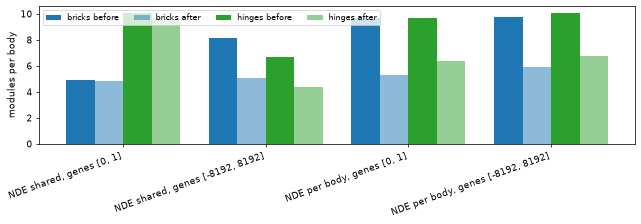

In [9]:
table = Table(title=f"{BODIES} bodies per genotype, mean per body")
for column in (
    "genotype",
    "overlapping",
    "modules",
    "bricks",
    "hinges",
    "removed",
):
    table.add_column(
        column, justify="left" if column == "genotype" else "right"
    )
for name in GENOTYPES:
    old, new = counts_before[name], counts_after[name]
    table.add_row(
        name,
        f"{overlapping[name]} of {BODIES}",
        *(f"{o:.1f} -> {n:.1f}" for o, n in zip(old, new, strict=True)),
        f"{1 - new[0] / old[0]:.0%}",
    )
console.print(table)

fig, axis = plt.subplots(figsize=(10, 3.5))
places = np.arange(len(GENOTYPES))
for shift, (label, column) in zip(
    (-0.3, -0.1, 0.1, 0.3),
    (
        ("bricks before", (counts_before, 1)),
        ("bricks after", (counts_after, 1)),
        ("hinges before", (counts_before, 2)),
        ("hinges after", (counts_after, 2)),
    ),
    strict=True,
):
    counts, index = column
    axis.bar(
        places + shift,
        [counts[name][index] for name in GENOTYPES],
        width=0.2,
        label=label,
        color=("tab:blue" if "brick" in label else "tab:green"),
        alpha=1.0 if "before" in label else 0.5,
    )
axis.set_xticks(places, list(GENOTYPES), rotation=20, ha="right")
axis.set_ylabel("modules per body")
axis.legend(ncols=4, fontsize="small")
plt.tight_layout()
plt.show()

In [10]:
assert table.row_count == len(GENOTYPES)
assert len(axis.patches) == 4 * len(GENOTYPES)  # four bars per genotype

## Density before and after repair

One figure per genotype. Top row: the bodies as decoded. Middle row: the same bodies after repair. Bottom row: after minus before; blue pixels lost modules, and nothing can turn red because repair only removes.

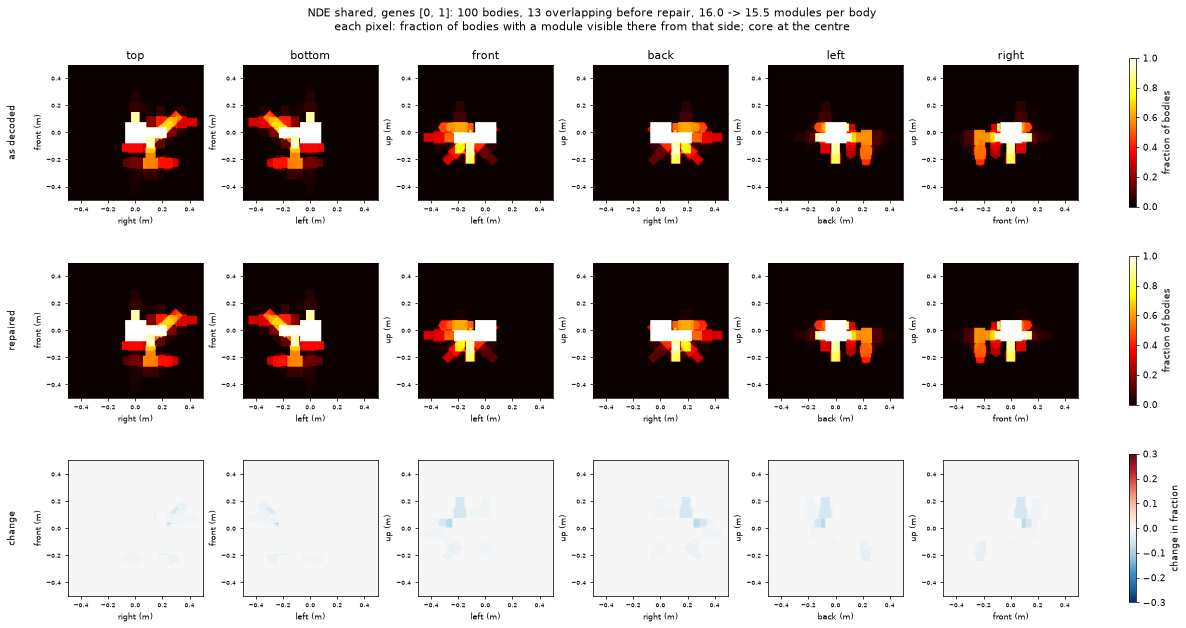

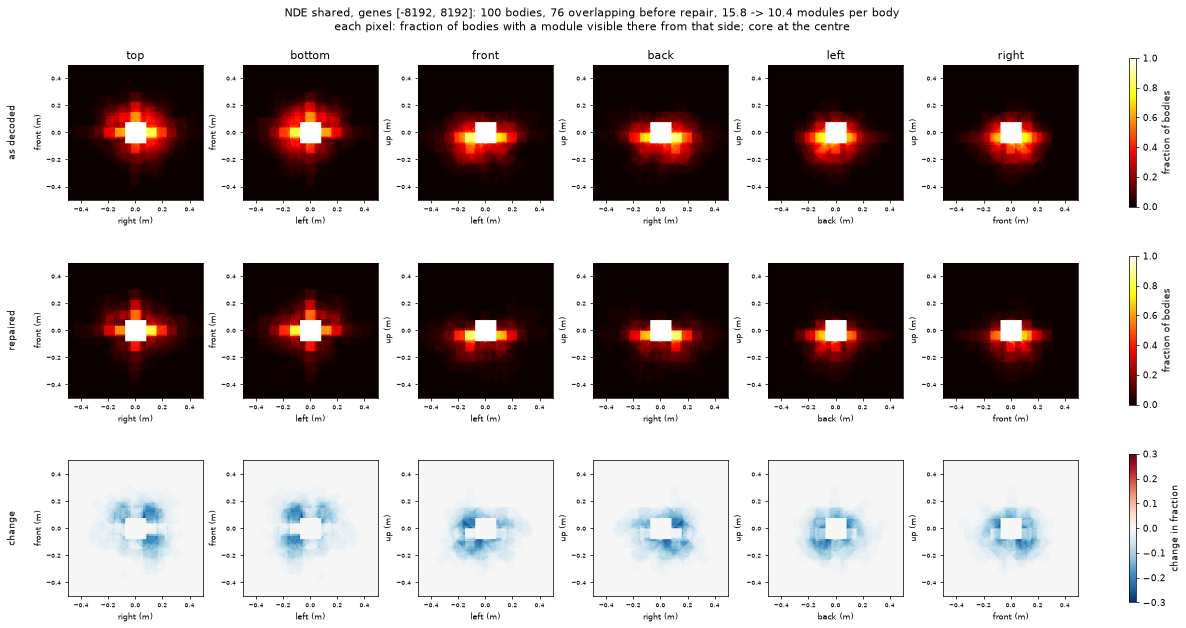

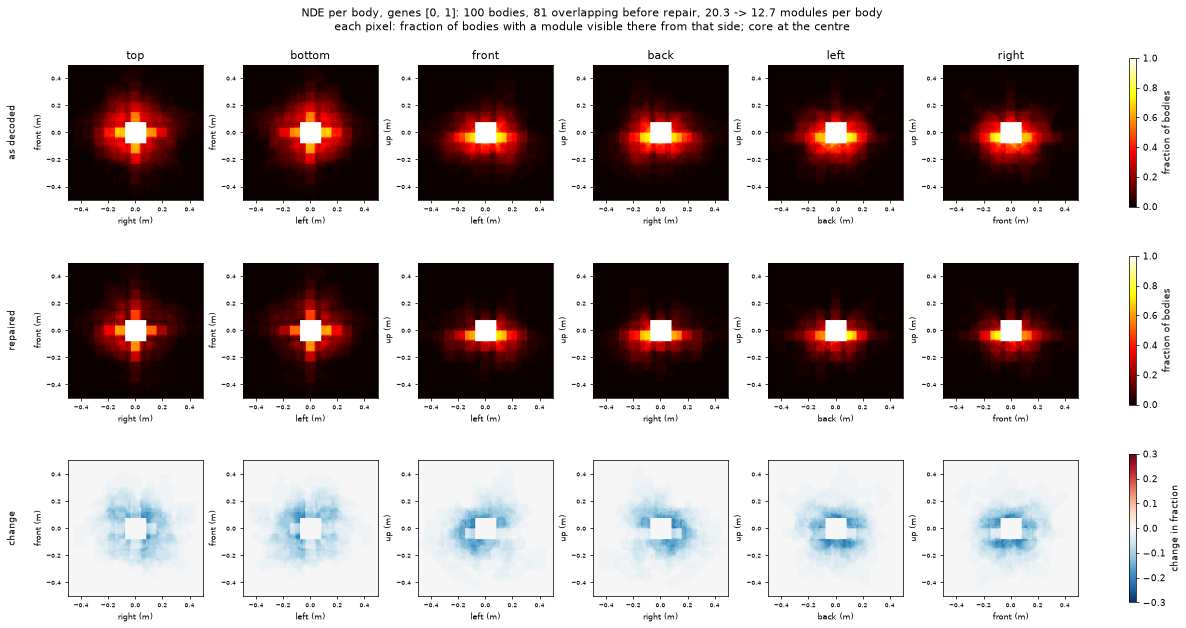

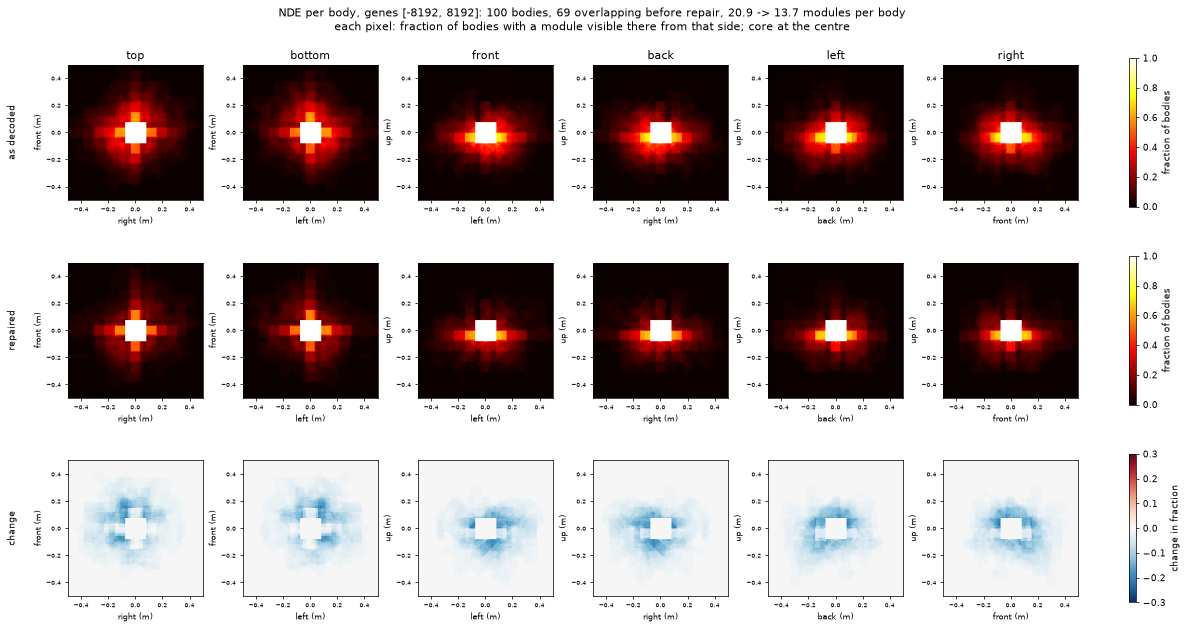

In [11]:
EXTENT = (-HALF, HALF, -HALF, HALF)
BAR_LABELS = (
    "fraction of bodies",
    "fraction of bodies",
    "change in fraction",
)
for name in GENOTYPES:
    fig, axes = plt.subplots(3, 6, figsize=(18, 9.5), layout="constrained")
    for column, (side, (_, _, _, labels)) in enumerate(VIEWS.items()):
        shown = (
            (before[name][side], "hot", 0.0, 1.0),
            (after[name][side], "hot", 0.0, 1.0),
            (after[name][side] - before[name][side], "RdBu_r", -0.3, 0.3),
        )
        for row, (image, colours, low, high) in enumerate(shown):
            axis = axes[row, column]
            picture = axis.imshow(
                image, cmap=colours, vmin=low, vmax=high, extent=EXTENT
            )
            axis.set_xlabel(labels[0], fontsize="small")
            axis.set_ylabel(labels[1], fontsize="small")
            axis.tick_params(labelsize="x-small")
            if column == len(VIEWS) - 1:
                bar = fig.colorbar(picture, ax=axes[row, :], shrink=0.8)
                bar.set_label(BAR_LABELS[row])
        axes[0, column].set_title(side)
    axes[0, 0].annotate(
        "as decoded",
        (-0.45, 0.5),
        xycoords="axes fraction",
        rotation=90,
        va="center",
    )
    axes[1, 0].annotate(
        "repaired",
        (-0.45, 0.5),
        xycoords="axes fraction",
        rotation=90,
        va="center",
    )
    axes[2, 0].annotate(
        "change",
        (-0.45, 0.5),
        xycoords="axes fraction",
        rotation=90,
        va="center",
    )
    fig.suptitle(
        f"{name}: {BODIES} bodies, {overlapping[name]} overlapping before "
        f"repair, {counts_before[name][0]:.1f} -> {counts_after[name][0]:.1f} "
        "modules per body\n"
        "each pixel: fraction of bodies with a module visible there "
        "from that side; core at the centre",
        fontsize="large",
    )
    plt.show()

In [12]:
for name in GENOTYPES:
    for side in VIEWS:
        assert before[name][side].min() >= 0
        assert after[name][side].max() <= 1 + 1e-9

## Checks

Repair keeps the core, never adds a module, and never grows a silhouette. Every genotype has bodies that overlap, so the repair has work to do in each.

In [13]:
for name in GENOTYPES:
    assert subsets[name]  # repaired bodies keep a subset of modules
    assert overlapping[name] > 0
    assert counts_after[name][0] <= counts_before[name][0]
    assert counts_after[name][0] >= 1  # the core always stays
    for side in VIEWS:
        assert np.all(after[name][side] <= before[name][side] + 1e-9)
        centre = after[name][side][PIXELS // 2, PIXELS // 2]
        assert np.isclose(centre, 1.0)  # every body has its core there